In [1]:
import pandas as pd
df= pd.read_csv(r'C:\Users\HAI\GUVI\Planetary_defense\pha_dataset.csv')
df.head()

C:\Users\HAI\AppData\Local\Temp\ipykernel_3332\481796315.py:2: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv(r'C:\Users\HAI\GUVI\Planetary_defense\pha_dataset.csv')


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [2]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplicate rows:", df.duplicated().sum())

(958524, 45)
['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class', 'rms']
id                 object
spkid               int64
full_name          object
pdes               object
name               object
prefix             object
neo                object
pha                object
H                 float64
diameter          float64
albedo            float64
diameter_sigma    float64
orbit_id           object
epoch             float64
epoch_mjd           int64
epoch_cal         float64
equinox            object
e                 float64
a                 float64
q                 float64
i                 float64
om                float64
w

### Cluster dataset

In [3]:
cluster_cols = [
    'a',
    'e',
    'i',
    'per',
    'moid_ld'
]

df_cluster = df[cluster_cols].copy()

print(df_cluster.shape)
print(df_cluster.isnull().sum())

(958524, 5)
a            0
e            0
i            0
per          4
moid_ld    127
dtype: int64


### Handle missing values

In [4]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

df_cluster[cluster_cols] = imputer.fit_transform(
    df_cluster[cluster_cols]
)

print(df_cluster.isnull().sum())
print(df_cluster.shape)

a          0
e          0
i          0
per        0
moid_ld    0
dtype: int64
(958524, 5)


### Check distributions and outliers

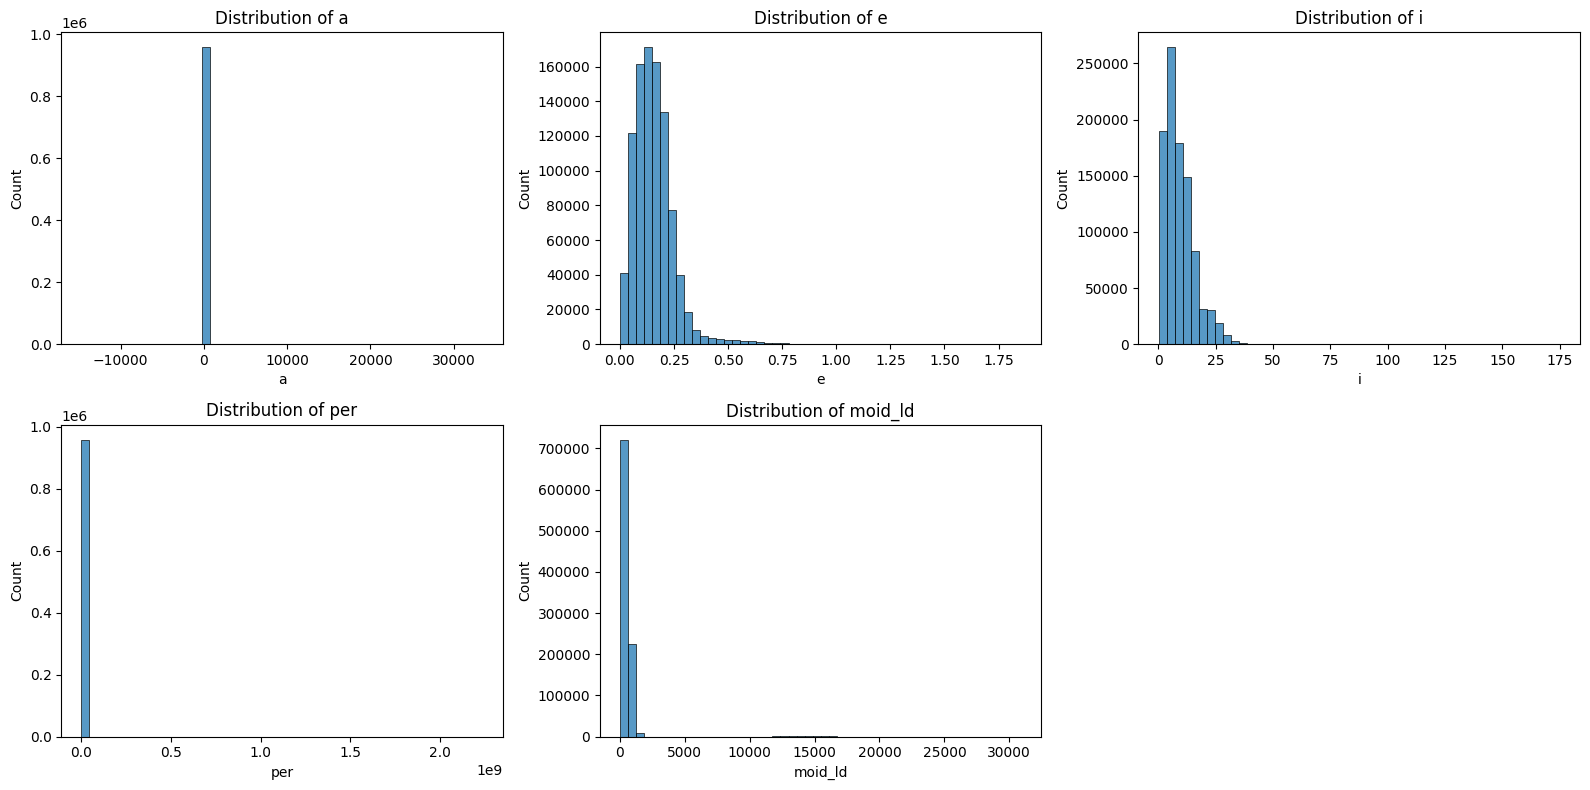

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(df_cluster.columns):
    sns.histplot(df_cluster[col], bins=50, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

#### Scale the features

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_cluster)

print(X_scaled.shape)

(958524, 5)


### Elbow Method

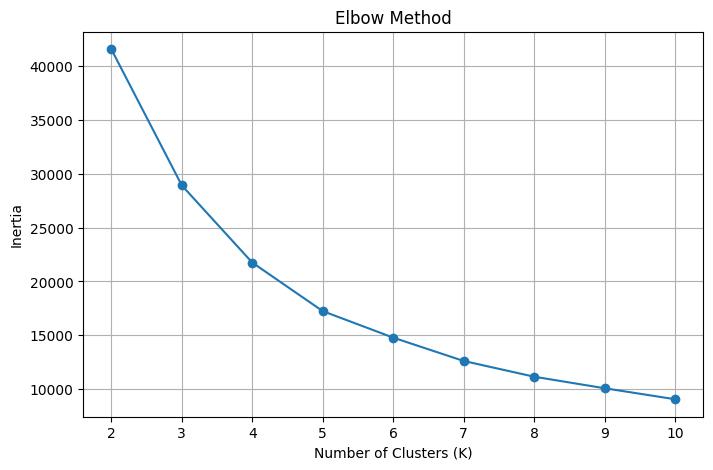

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Take a sample to speed up the search
import numpy as np

rng = np.random.RandomState(42)
sample_size = min(20000, len(X_scaled))
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_idx]

# Calculate inertia for different K values
inertia = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_sample)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## Calculate the Silhouette Score

In [8]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.9003
K = 3, Silhouette Score = 0.3985
K = 4, Silhouette Score = 0.3585
K = 5, Silhouette Score = 0.3481
K = 6, Silhouette Score = 0.3547
K = 7, Silhouette Score = 0.3507
K = 8, Silhouette Score = 0.3496
K = 9, Silhouette Score = 0.3432
K = 10, Silhouette Score = 0.3444


In [9]:
from sklearn.cluster import KMeans
import pandas as pd

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_2 = kmeans_2.fit_predict(X_sample)

print(pd.Series(labels_2).value_counts().sort_index())

0    19930
1       70
Name: count, dtype: int64


In [10]:
sample_df = df_cluster.iloc[sample_idx].copy()
sample_df['cluster'] = labels_2

print(
    sample_df.groupby('cluster')[
        ['a', 'e', 'i', 'per', 'moid_ld']
    ].median().round(3)
)

print(
    sample_df['cluster'].value_counts(normalize=True)
      .sort_index()
      .mul(100)
      .round(2)
)

              a      e      i         per    moid_ld
cluster                                             
0         2.646  0.144  7.328    1571.719    478.953
1        44.221  0.151  8.025  107410.186  14396.741
cluster
0    99.65
1     0.35
Name: proportion, dtype: float64


In [12]:
from sklearn.cluster import KMeans
import pandas as pd

sample_df = df_cluster.iloc[sample_idx].copy()

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    sample_df[f'cluster_{k}'] = model.fit_predict(X_sample)

    print(f"\n--- K = {k}: Cluster proportions (%) ---")
    print(
        sample_df[f'cluster_{k}']
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )

    print(f"\n--- K = {k}: Median orbital characteristics ---")
    display(
        sample_df.groupby(f'cluster_{k}')[
            ['a', 'e', 'i', 'per', 'moid_ld']
        ].median().round(3)
    )


--- K = 2: Cluster proportions (%) ---
cluster_2
0    99.65
1     0.35
Name: proportion, dtype: float64

--- K = 2: Median orbital characteristics ---


,a,e,i,per,moid_ld
cluster_2,,,,,
0,2.646,0.144,7.328,1571.719,478.953
1,44.221,0.151,8.025,107410.186,14396.741



--- K = 3: Cluster proportions (%) ---
cluster_3
0    29.30
1     0.35
2    70.34
Name: proportion, dtype: float64

--- K = 3: Median orbital characteristics ---


,a,e,i,per,moid_ld
cluster_3,,,,,
0,2.669,0.195,14.870,1592.925,454.301
1,44.221,0.151,8.025,107410.186,14396.741
2,2.628,0.129,5.472,1556.133,492.121



--- K = 4: Cluster proportions (%) ---
cluster_4
0    55.12
1    21.95
2     0.35
3    22.58
Name: proportion, dtype: float64

--- K = 4: Median orbital characteristics ---


,a,e,i,per,moid_ld
cluster_4,,,,,
0,2.671,0.113,5.592,1594.386,531.855
1,2.691,0.144,16.187,1612.502,520.523
2,44.221,0.151,8.025,107410.186,14396.741
3,2.574,0.236,6.466,1508.684,354.867


In [13]:
for k in [3, 4]:
    print(f"\n========== K = {k} ==========")

    print(
        sample_df.groupby(f'cluster_{k}')[
            ['a', 'e', 'i', 'per', 'moid_ld']
        ].median().round(3)
    )


========== K = 3 ==========
                a      e       i         per    moid_ld
cluster_3                                              
0           2.669  0.195  14.870    1592.925    454.301
1          44.221  0.151   8.025  107410.186  14396.741
2           2.628  0.129   5.472    1556.133    492.121

========== K = 4 ==========
                a      e       i         per    moid_ld
cluster_4                                              
0           2.671  0.113   5.592    1594.386    531.855
1           2.691  0.144  16.187    1612.502    520.523
2          44.221  0.151   8.025  107410.186  14396.741
3           2.574  0.236   6.466    1508.684    354.867


In [15]:
cluster_names = {
    0: 'Low Eccentricity - Low Inclination',
    1: 'High Inclination',
    2: 'Large Orbital Scale - Long Period',
    3: 'High Eccentricity'
}

sample_df['cluster_name'] = (
    sample_df['cluster_4'].map(cluster_names)
)

display(sample_df[
    ['a', 'e', 'i', 'per', 'moid_ld',
     'cluster_4', 'cluster_name']
].head())

,a,e,i,per,moid_ld,cluster_4,cluster_name
323650,2.268877,0.139451,3.187887,1248.288493,376.725900,0,Low Eccentricity - Low Inclination
571724,2.572391,0.245938,10.313243,1506.967518,377.926100,3,High Eccentricity
395983,2.714802,0.112879,4.108604,1633.825582,550.500424,0,Low Eccentricity - Low Inclination
235862,3.113143,0.175246,9.697628,2006.304939,615.733099,0,Low Eccentricity - Low Inclination
651830,2.753819,0.181327,7.148554,1669.173818,496.845556,0,Low Eccentricity - Low Inclination
